# m07 - Unsupervised Agro-Ecological Zones

No labels here: group the 9,333 cells purely by their physical drivers (14 climate, soil and terrain variables) and check
whether the zones that emerge line up with the crop recommendations derived from GAEZ.

1. **How many zones?** K-means and Gaussian-mixture sweeps over k = 2 ... 12 (silhouette, Calinski-Harabasz, Davies-Bouldin, BIC).
2. **Which algorithm?** K-means, Gaussian mixture, Ward hierarchical, and spatially constrained Ward (neighbours on the grid
   may merge only if they are adjacent) at the same k, scored on cluster quality, spatial contiguity and agreement with the
   crop-recommendation labels (ARI / NMI).
3. **Are the zones stable?** Bootstrap re-clustering and agreement between runs.
4. **What do the zones look like?** Maps, feature profiles and crop-label composition.

In [1]:
import sys
from pathlib import Path

# Make exp_lib importable no matter where the notebook is launched from.
HERE = next(p for p in (Path.cwd(), Path.cwd() / "scripts" / "modeling") if (p / "exp_lib.py").exists())
sys.path.insert(0, str(HERE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import exp_lib as E
from threadpoolctl import threadpool_limits

threadpool_limits(E.N_JOBS)   # BLAS/OpenMP in this kernel stay within the same CPU budget as the worker pool
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)

In [2]:
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score,
                             normalized_mutual_info_score, silhouette_score)
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import kneighbors_graph
from sklearn.preprocessing import StandardScaler

df = E.load_table()
base = E.feature_columns()
Z = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(df[base]))
labels_thr = E.crop_labels(df, "thresh").to_numpy()
labels_top = E.crop_labels(df, "top").to_numpy()
pca = PCA(n_components=0.95, random_state=0).fit(Z)
print(f"{Z.shape[1]} standardised features; {pca.n_components_} principal components keep 95% of the variance")
pca_var = pd.Series(pca.explained_variance_ratio_, index=[f"PC{i+1}" for i in range(pca.n_components_)]).round(3)
pca_var.to_frame("explained_variance_ratio").T

14 standardised features; 8 principal components keep 95% of the variance


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
explained_variance_ratio,0.488,0.17,0.113,0.062,0.042,0.032,0.028,0.02


## 1. How many zones?

D:\Softwares\Anaconda\Miniconda\envs\geoai-suitability\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


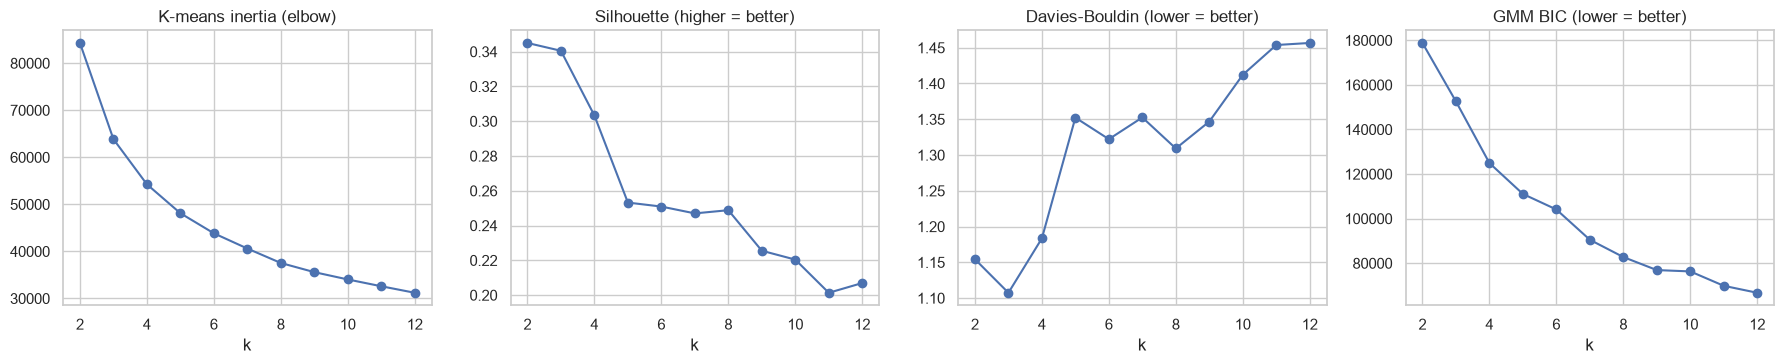

,kmeans_inertia,silhouette,calinski_harabasz,davies_bouldin,gmm_bic,gmm_aic
k,,,,,,
2,84300.609,0.345,5131.614,1.154,178820.550,177113.776
3,63864.139,0.341,4879.297,1.107,152606.577,150042.846
4,54260.436,0.303,4378.580,1.184,124942.483,121521.795
5,48116.247,0.253,4000.666,1.352,111073.171,106795.525
6,43849.114,0.251,3693.146,1.322,104102.815,98968.212
7,40609.727,0.247,3446.760,1.353,90512.123,84520.562
8,37539.728,0.249,3304.566,1.309,82757.419,75908.901
9,35592.411,0.226,3113.127,1.347,76913.296,69207.821
10,34040.044,0.220,2940.366,1.412,76313.971,67751.538


In [3]:
rows = []
for k in range(2, 13):
    km = KMeans(k, n_init=10, random_state=0).fit(Z)
    gm = GaussianMixture(k, covariance_type="full", n_init=3, random_state=0).fit(Z)
    rows.append({"k": k, "kmeans_inertia": km.inertia_, "silhouette": silhouette_score(Z, km.labels_),
                 "calinski_harabasz": calinski_harabasz_score(Z, km.labels_), "davies_bouldin": davies_bouldin_score(Z, km.labels_),
                 "gmm_bic": gm.bic(Z), "gmm_aic": gm.aic(Z)})
sweep = pd.DataFrame(rows).set_index("k")
E.save_table(sweep.round(3), "m07_k_sweep", index=True)
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, col, title in zip(axes, ["kmeans_inertia", "silhouette", "davies_bouldin", "gmm_bic"],
                          ["K-means inertia (elbow)", "Silhouette (higher = better)", "Davies-Bouldin (lower = better)", "GMM BIC (lower = better)"]):
    ax.plot(sweep.index, sweep[col], marker="o"); ax.set(title=title, xlabel="k")
plt.tight_layout()
E.save_fig(fig, "m07_k_sweep")
plt.show()
sweep.round(3)

## 2. Algorithms at a fixed k

In [4]:
K = int(sweep["silhouette"].iloc[2:].idxmax())   # best silhouette among k >= 4 (k = 2 or 3 only separates coast from uplands)
print("chosen k =", K)

grid_conn = kneighbors_graph(df[["row", "col"]].to_numpy(), n_neighbors=8, include_self=False)
algos = {
    "kmeans": KMeans(K, n_init=20, random_state=0).fit_predict(Z),
    "gmm": GaussianMixture(K, covariance_type="full", n_init=5, random_state=0).fit_predict(Z),
    "ward": AgglomerativeClustering(K, linkage="ward").fit_predict(Z),
    "ward + spatial": AgglomerativeClustering(K, linkage="ward", connectivity=grid_conn).fit_predict(Z),
}

r, c = df["row"].to_numpy(), df["col"].to_numpy()
shape = (r.max() + 1, c.max() + 1)
def contiguity(lab):
    m = np.full(shape, -1); m[r, c] = lab
    right = (m[:, :-1] >= 0) & (m[:, 1:] >= 0); down = (m[:-1, :] >= 0) & (m[1:, :] >= 0)
    same = ((m[:, :-1] == m[:, 1:]) & right).sum() + ((m[:-1, :] == m[1:, :]) & down).sum()
    return same / (right.sum() + down.sum())

from scipy.ndimage import label as cc_label
def n_components(lab):
    m = np.full(shape, -1); m[r, c] = lab
    return sum(cc_label(m == k)[1] for k in np.unique(lab))

rows = []
for name, lab in algos.items():
    rows.append({"algorithm": name, "silhouette": silhouette_score(Z, lab), "calinski_harabasz": calinski_harabasz_score(Z, lab),
                 "davies_bouldin": davies_bouldin_score(Z, lab), "neighbour_agreement": contiguity(lab),
                 "connected_patches": n_components(lab), "ARI_vs_label": adjusted_rand_score(labels_thr, lab),
                 "NMI_vs_label": normalized_mutual_info_score(labels_thr, lab), "NMI_vs_top_crop": normalized_mutual_info_score(labels_top, lab)})
cmp_ = pd.DataFrame(rows).set_index("algorithm")
E.save_table(cmp_.round(4), "m07_algorithms", index=True)
cmp_.round(3)

chosen k = 4


D:\Softwares\Anaconda\Miniconda\envs\geoai-suitability\Lib\site-packages\sklearn\cluster\_agglomerative.py:322: UserWarning: the number of connected components of the connectivity matrix is 3 > 1. Completing it to avoid stopping the tree early.
  connectivity, n_connected_components = _fix_connectivity(


,silhouette,calinski_harabasz,davies_bouldin,neighbour_agreement,connected_patches,ARI_vs_label,NMI_vs_label,NMI_vs_top_crop
algorithm,,,,,,,,
kmeans,0.303,4378.580,1.184,0.954,52,0.157,0.223,0.394
gmm,0.192,2875.499,1.663,0.960,49,0.211,0.262,0.354
ward,0.280,4048.579,1.321,0.964,36,0.143,0.211,0.402
ward + spatial,0.273,3798.656,1.198,0.973,15,0.178,0.247,0.425


## 3. Stability under resampling

In [5]:
rng = np.random.default_rng(0)
ref = KMeans(K, n_init=20, random_state=0).fit(Z)
aris = []
for b in range(30):
    idx = rng.choice(len(Z), size=len(Z), replace=True)
    km = KMeans(K, n_init=5, random_state=b).fit(Z[idx])
    aris.append(adjusted_rand_score(ref.labels_, km.predict(Z)))
stab = pd.Series(aris, name="ARI vs reference clustering")
print(f"K-means bootstrap stability (k={K}): mean ARI {stab.mean():.3f}, min {stab.min():.3f}")
E.save_table(stab.describe().to_frame().round(4), "m07_stability", index=True)

# stability across k: do the same cells stay together as k grows?
ks = [3, 4, 5, 6, 8, 10]
stab_k = {}
for k in ks:
    runs = [KMeans(k, n_init=1, random_state=s).fit_predict(Z) for s in range(10)]
    stab_k[k] = np.mean([adjusted_rand_score(runs[i], runs[j]) for i in range(10) for j in range(i + 1, 10)])
pd.Series(stab_k, name="mean pairwise ARI between 10 random starts").round(3).to_frame().T

K-means bootstrap stability (k=4): mean ARI 0.982, min 0.952


,3,4,5,6,8,10
mean pairwise ARI between 10 random starts,0.733,0.71,0.9,0.727,0.879,0.788


## 4. What do the zones look like?

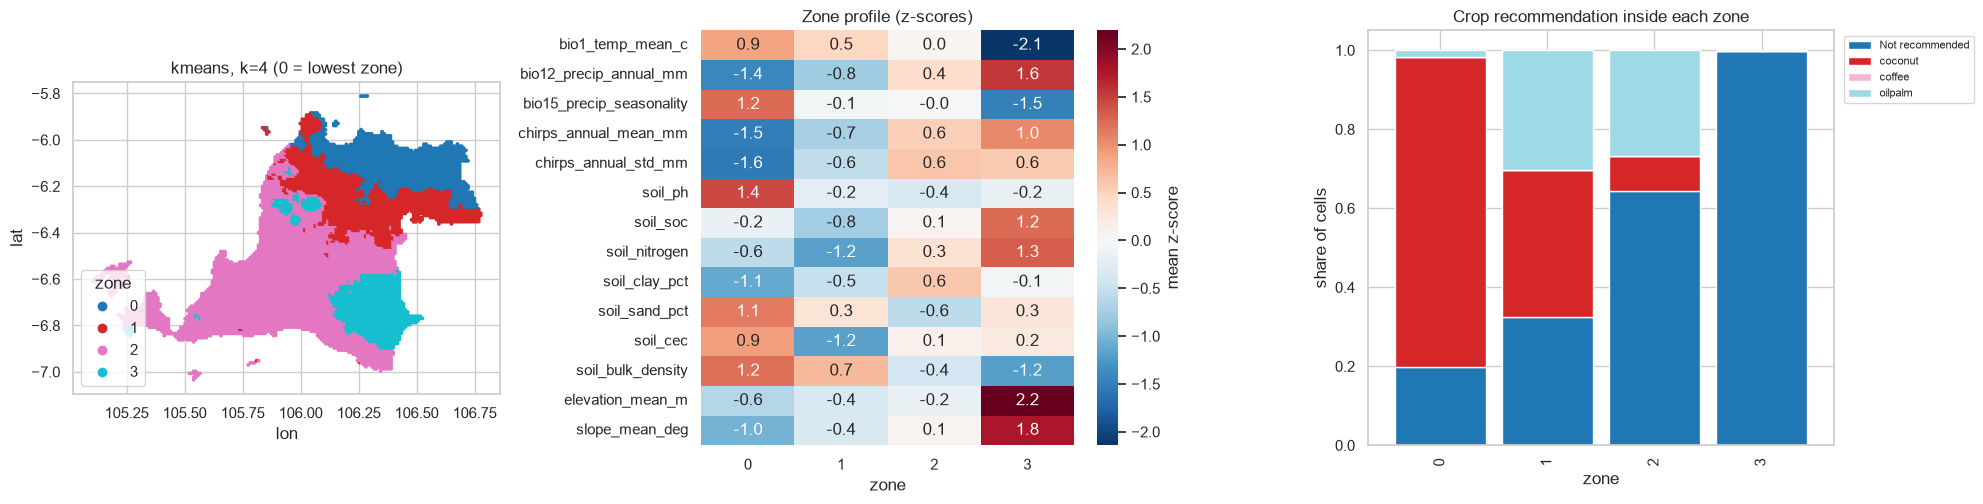

col_0,Not recommended,coconut,coffee,oilpalm
row_0,,,,
0,0.199,0.784,0.000,0.017
1,0.325,0.370,0.000,0.304
2,0.644,0.088,0.001,0.267
3,0.997,0.000,0.000,0.003


In [6]:
name = "kmeans"
lab = algos[name]
order = pd.Series(df["elevation_mean_m"].fillna(df["elevation_mean_m"].median())).groupby(lab).mean().sort_values().index
rank = {old: new for new, old in enumerate(order)}          # zone 0 = lowest mean elevation
lab = np.array([rank[v] for v in lab])

fig, axes = plt.subplots(1, 3, figsize=(20, 5.2), gridspec_kw={"width_ratios": [1.1, 1.2, 1.2]})
sc = axes[0].scatter(df["lon"], df["lat"], c=lab, s=3, cmap="tab10")
axes[0].set(title=f"{name}, k={K} (0 = lowest zone)", xlabel="lon", ylabel="lat", aspect="equal")
axes[0].legend(*sc.legend_elements(), title="zone", loc="lower left", markerscale=1)

prof = pd.DataFrame(Z, columns=base).groupby(lab).mean()
sns.heatmap(prof.T, annot=True, fmt=".1f", cmap="RdBu_r", center=0, ax=axes[1], cbar_kws={"label": "mean z-score"})
axes[1].set(title="Zone profile (z-scores)", xlabel="zone", ylabel="")

comp = pd.crosstab(lab, labels_thr, normalize="index")
comp.plot.bar(stacked=True, ax=axes[2], colormap="tab20", width=0.85)
axes[2].set(title="Crop recommendation inside each zone", xlabel="zone", ylabel="share of cells")
axes[2].legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
E.save_fig(fig, "m07_zones")
plt.show()
E.save_table(comp.round(4), "m07_zone_label_composition", index=True)
comp.round(3)

In [7]:
# Cluster directly on the ten GAEZ indices: how much do crop-suitability zones agree with the physical zones?
Zg = StandardScaler().fit_transform(df[E.gaez_cols()])
rows = []
for k in [3, 4, 5, 6, 8]:
    phys = KMeans(k, n_init=10, random_state=0).fit_predict(Z)
    gz = KMeans(k, n_init=10, random_state=0).fit_predict(Zg)
    rows.append({"k": k, "ARI": adjusted_rand_score(phys, gz), "NMI": normalized_mutual_info_score(phys, gz)})
agree = pd.DataFrame(rows).set_index("k")
E.save_table(agree.round(4), "m07_physical_vs_gaez_zones", index=True)
agree.round(3)

,ARI,NMI
k,,
3,0.221,0.275
4,0.186,0.257
5,0.218,0.282
6,0.190,0.289
8,0.158,0.290
